<a href="https://colab.research.google.com/github/samarg4617-creator/imageprocess/blob/main/assingment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

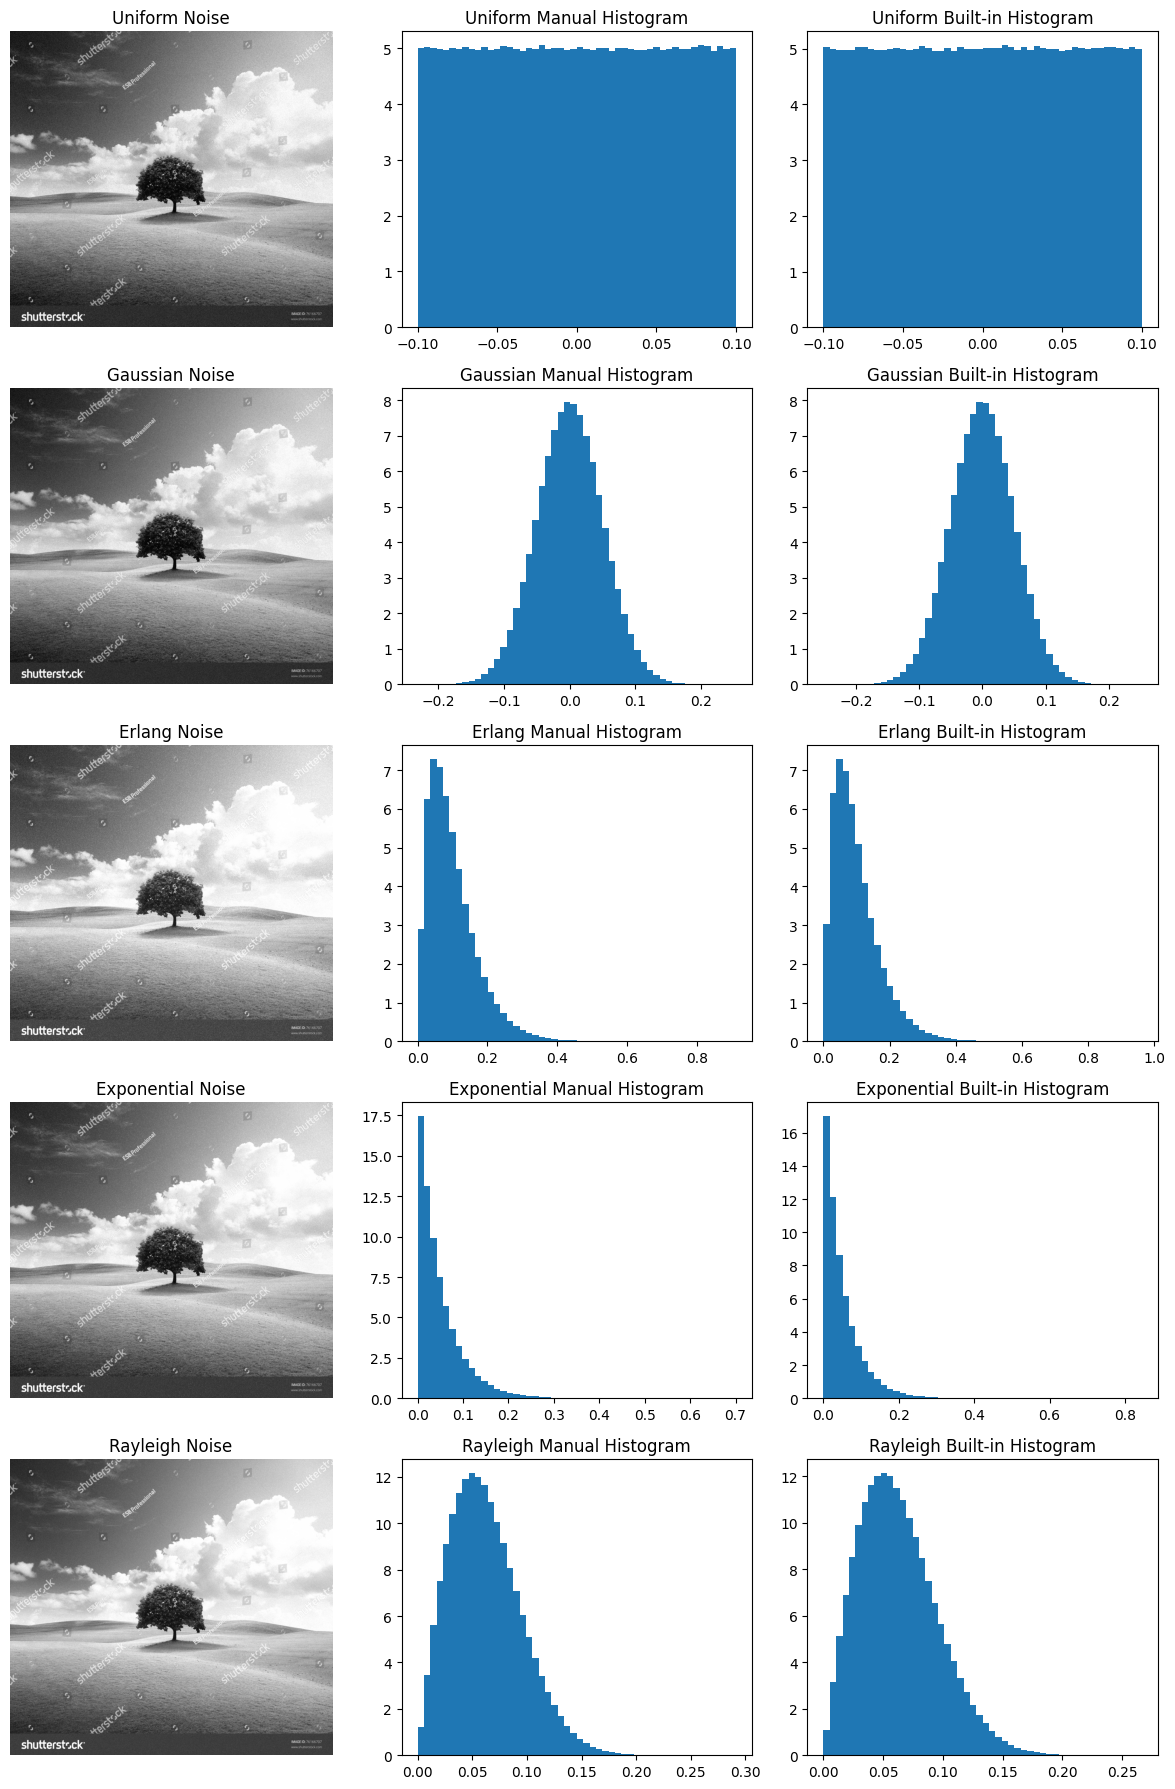

In [1]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
img = cv2.imread("sampleimage.jpg", 0)

if img is None:
    print("Image not found!")
    exit()

img = img.astype(float) / 255.0
M, N = img.shape

np.random.seed(10)

# Parameters
a = -0.1
b = 0.1
mu = 0
sigma = 0.05
alpha = 2
beta = 0.05

# 1. Uniform noise using PDF: p(z) = 1/(b-a)
u = np.random.rand(M, N)
uniform = a + (b - a) * u

# 2. Gaussian noise using inverse CDF
u1 = np.random.rand(M, N)
u2 = np.random.rand(M, N)
gaussian = mu + sigma * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)

# 3. Erlang noise (Gamma distribution with integer shape alpha)

erlang = np.zeros((M, N))
for i in range(alpha):
    erlang += -beta * np.log(np.random.rand(M, N))

# 4. Exponential noise using inverse CDF
exponential = -beta * np.log(np.random.rand(M, N))

u3 = np.random.rand(M, N)
rayleigh = np.sqrt(-2 * beta**2 * np.log(1 - u3))

uniform_builtin = np.random.uniform(a, b, (M, N))
gaussian_builtin = np.random.normal(mu, sigma, (M, N))
erlang_builtin = np.random.gamma(alpha, beta, (M, N))
exponential_builtin = np.random.exponential(beta, (M, N))
rayleigh_builtin = np.random.rayleigh(beta, (M, N))

noises = [
    ("Uniform", uniform, uniform_builtin),
    ("Gaussian", gaussian, gaussian_builtin),
    ("Erlang", erlang, erlang_builtin),
    ("Exponential", exponential, exponential_builtin),
    ("Rayleigh", rayleigh, rayleigh_builtin)
]

plt.figure(figsize=(12, 18))

for i, (name, manual, builtin) in enumerate(noises):

    noisy = np.clip(img + manual, 0, 1)

    plt.subplot(5, 3, 3*i + 1)
    plt.imshow(noisy, cmap="gray", vmin=0, vmax=1)
    plt.title(name + " Noise")
    plt.axis("off")

    plt.subplot(5, 3, 3*i + 2)
    plt.hist(manual.ravel(), bins=50, density=True)
    plt.title(name + " Manual Histogram")

    plt.subplot(5, 3, 3*i + 3)
    plt.hist(builtin.ravel(), bins=50, density=True)
    plt.title(name + " Built-in Histogram")

plt.tight_layout()
plt.show()
